In [1]:
# Import the pandas library, which is the standard tool for handling data tables in Python
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset into a DataFrame (a data table)
df = pd.read_csv('Ecommerce_Delivery_Analytics_New.csv')

This code imports the `pandas` library, a standard tool for data manipulation in Python, and subsequently loads the `Ecommerce_Delivery_Analytics_New.csv` dataset into a pandas DataFrame, which is a tabular data structure.

In [2]:
# 2. Display the first 5 rows to understand what columns we have
print("--- First 5 Rows of Data ---")
display(df.head())

--- First 5 Rows of Data ---


,Order ID,Customer ID,Platform,Order Date & Time,Delivery Time (Minutes),Product Category,Order Value (INR),Customer Feedback,Service Rating,Delivery Delay,Refund Requested
0,ORD000001,CUST2824,JioMart,19:29.5,30,Fruits & Vegetables,382,"Fast delivery, great service!",5,No,No
1,ORD000002,CUST1409,Blinkit,54:29.5,16,Dairy,279,Quick and reliable!,5,No,No
2,ORD000003,CUST5506,JioMart,21:29.5,25,Beverages,599,Items missing from order.,2,No,Yes
3,ORD000004,CUST5012,JioMart,19:29.5,42,Beverages,946,Items missing from order.,2,Yes,Yes
4,ORD000005,CUST4657,Blinkit,49:29.5,30,Beverages,334,"Fast delivery, great service!",5,No,No


The initial five rows of the DataFrame are displayed to provide an overview of the dataset's structure and content.

In [3]:
# 3. Check how many reviews belong to each quick-commerce platform
print("\n--- Total Reviews by Platform ---")
platform_counts = df['Platform'].value_counts()
print(platform_counts)


--- Total Reviews by Platform ---
Platform
Swiggy Instamart    33449
Blinkit             33424
JioMart             33127
Name: count, dtype: int64


This analysis quantifies the distribution of customer reviews across different quick-commerce platforms within the dataset.

In [4]:
# 4. Look at the spread of Service Ratings (1 to 5 stars)
print("\n--- Distribution of Star Ratings ---")
rating_counts = df['Service Rating'].value_counts().sort_index()
print(rating_counts)


--- Distribution of Star Ratings ---
Service Rating
1    15267
2    30552
3     7704
4     7789
5    38688
Name: count, dtype: int64


The distribution of 'Service Rating' (1 to 5 stars) within the dataset is presented, indicating the frequency of each rating.

In [5]:
# 5. Let's see the most common textual complaints for the bad reviews (1 and 2 stars)
# We filter the table to only keep rows where the rating is 2 or lower
bad_reviews = df[df['Service Rating'] <= 2]

The DataFrame is filtered to isolate reviews with a 'Service Rating' of 1 or 2 stars, classifying these as 'negative experiences' for further analysis.

In [6]:
print("\n--- Top 5 Complaints in Bad Reviews ---")
# Count how many times each specific text feedback appears in the bad reviews
top_complaints = bad_reviews['Customer Feedback'].value_counts().head(5)
print(top_complaints)


--- Top 5 Complaints in Bad Reviews ---
Customer Feedback
Wrong item delivered.             7738
Items missing from order.         7737
Delivery person was rude.         7643
Very late delivery, not happy.    7592
Not fresh, disappointed.          7580
Name: count, dtype: int64


This segment identifies and displays the top 5 most frequently occurring customer feedback comments within the subset of negative reviews.

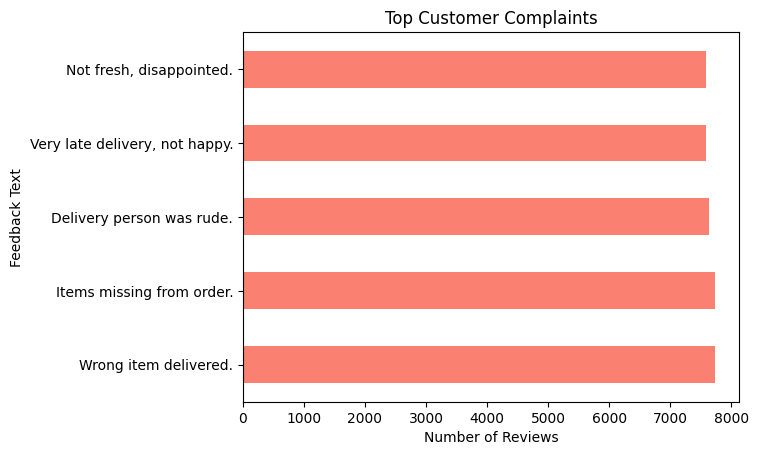

In [7]:
# A simple bar chart to make it visual for your presentation
top_complaints.plot(kind='barh', color='salmon', title='Top Customer Complaints')
plt.xlabel('Number of Reviews')
plt.ylabel('Feedback Text')
plt.show()

I created a simple bar chart to visually show the top complaints, making it easy to understand.

In [8]:
# Import the tools we need for cleaning and visualizing text
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1. Download the language dictionaries NLTK needs behind the scenes
nltk.download('stopwords')
nltk.download('wordnet')

# The dataset should already be loaded at this point, removed redundant load
# df = pd.read_csv('Ecommerce_Delivery_Analytics_New.csv')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

Essential libraries for text cleaning and visualization, including `pandas`, `re`, `nltk`, `wordcloud`, and `matplotlib.pyplot`, are imported. Additionally, necessary NLTK data resources, such as 'stopwords' and 'wordnet', are downloaded.

In [9]:
# 2. Set up our cleaning tools
lemmatizer = WordNetLemmatizer()
# Get standard English filler words, but KEEP 'not', 'no', and 'never'.
# If we delete "not", then "not fresh" becomes just "fresh", which ruins our analysis!
stop_words = set(stopwords.words('english')) - {'not', 'no', 'never'}

The `WordNetLemmatizer` is initialized for lemmatization, and a customized set of English stop words is created. Crucially, negative terms such as 'not', 'no', and 'never' are retained to preserve their significant impact on sentiment.

In [10]:
# 3. Create the cleaning recipe (function)
def clean_review(text):
    # Step A: Lowercase everything and keep only English letters and spaces (removes punctuation/numbers)
    text = re.sub(r'[^a-zA-Z\s]', '', str(text).lower())

    # Step B: Split the sentence into words, check if they are stop words, and lemmatize them
    # Lemmatizing means turning words like "delivered" or "delivering" into their base root: "deliver"
    words = [lemmatizer.lemmatize(word) for word in text.split() if word not in stop_words]

    # Step C: Glue the clean words back together into a sentence
    return " ".join(words)

print("Cleaning 100,000 rows of text... This will take a moment!")
# Apply our recipe to every single row in the dataset
df['Cleaned_Feedback'] = df['Customer Feedback'].apply(clean_review)

Cleaning 100,000 rows of text... This will take a moment!


A `clean_review` function is defined to preprocess text by converting it to lowercase, removing non-alphabetic characters, performing lemmatization, and eliminating common stop words. This function is then applied to the 'Customer Feedback' column, creating a new 'Cleaned_Feedback' column.

In [11]:
# --- UNIGRAM ANALYSIS & WORD CLOUDS ---

# Let's split the clean text into two buckets: Happy customers (4-5 stars) and Angry customers (1-2 stars)
positive_reviews = " ".join(df[df['Service Rating'] >= 4]['Cleaned_Feedback'])
negative_reviews = " ".join(df[df['Service Rating'] <= 2]['Cleaned_Feedback'])

# Function to draw the Word Cloud picture
def plot_wordcloud(text, title, colormap):
    # Create the word cloud object
    wordcloud = WordCloud(width=600, height=300, background_color='white', colormap=colormap, max_words=50).generate(text)

    # Display the image
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=20, fontweight='bold')
    plt.axis('off') # Hide the graph axes
    plt.show()

Cleaned customer feedback is segmented into 'positive_reviews' (4-5 stars) and 'negative_reviews' (1-2 stars). A `plot_wordcloud` function is also defined to generate visual representations of word frequencies.


Generating Word Clouds...


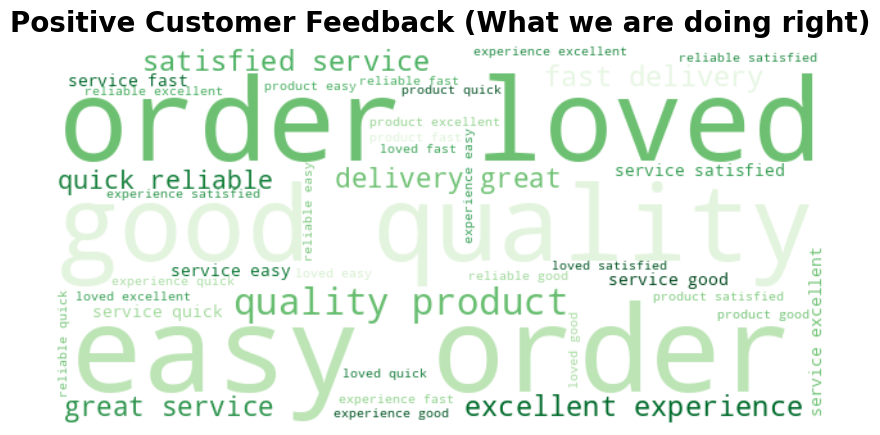

In [12]:
# 4. Generate the two Word Clouds
print("\nGenerating Word Clouds...")
plot_wordcloud(positive_reviews, "Positive Customer Feedback (What we are doing right)", 'Greens')


The `plot_wordcloud` function is invoked to visualize the most prominent terms in positive customer feedback, providing insights into areas of customer satisfaction.

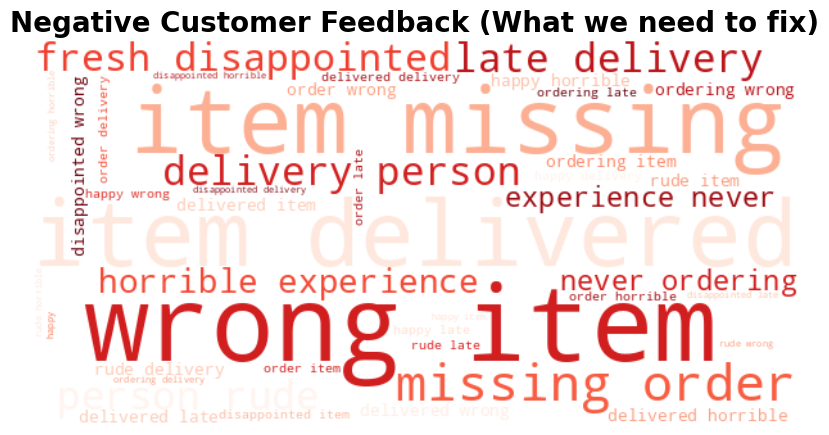

In [13]:
plot_wordcloud(negative_reviews, "Negative Customer Feedback (What we need to fix)", 'Reds')

A word cloud is generated for negative customer feedback, illustrating the most frequently used terms associated with dissatisfaction.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# 1. Feature Extraction: Tri-gram Analysis using TF-IDF
print("--- 1. Extracting Tri-grams using TF-IDF ---")

# We set up TF-IDF to look specifically for 3-word combinations (ngram_range=(3,3))
# We limit it to the top 15 most important phrases so our data doesn't get cluttered
tfidf = TfidfVectorizer(ngram_range=(3, 3), max_features=15)

# Fit the TF-IDF model on our cleaned text from Phase 2
tfidf_matrix = tfidf.fit_transform(df['Cleaned_Feedback'])

# Get the actual text of these top tri-grams
top_trigrams = tfidf.get_feature_names_out()
print("Top 15 Business Drivers (Tri-grams):")
for phrase in top_trigrams:
    print(f"- {phrase}")

--- 1. Extracting Tri-grams using TF-IDF ---
Top 15 Business Drivers (Tri-grams):
- delivery great service
- delivery not happy
- delivery person rude
- easy order loved
- experience never ordering
- fast delivery great
- good quality product
- horrible experience never
- item missing order
- late delivery not
- not fresh disappointed
- packaging could better
- wrong item delivered


TF-IDF (Term Frequency-Inverse Document Frequency) is applied to identify and extract the top 15 most significant three-word phrases (tri-grams) from the `Cleaned_Feedback` data. This analysis highlights key business drivers and prevalent thematic concerns.

In [15]:
# 2. Sentiment Analysis
print("\n--- 2. Calculating Sentiment Scores ---")

import nltk
nltk.download('vader_lexicon')

# Initialize VADER (Valence Aware Dictionary and sEntiment Reasoner)
# VADER is a best-in-class tool specifically built for social media and short reviews
sia = SentimentIntensityAnalyzer()

# Calculate a compound score for every review (-1.0 is extremely angry, +1.0 is extremely happy)
df['Sentiment_Score'] = df['Cleaned_Feedback'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Let's peek at the scores for a few reviews
print(df[['Customer Feedback', 'Service Rating', 'Sentiment_Score']].head())



--- 2. Calculating Sentiment Scores ---


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


               Customer Feedback  Service Rating  Sentiment_Score
0  Fast delivery, great service!               5           0.6249
1            Quick and reliable!               5           0.0000
2      Items missing from order.               2          -0.2960
3      Items missing from order.               2          -0.2960
4  Fast delivery, great service!               5           0.6249


The VADER (Valence Aware Dictionary and sEntiment Reasoner) lexicon is downloaded, and the `SentimentIntensityAnalyzer` is initialized. A 'Sentiment_Score' (compound score ranging from -1.0 to +1.0) is subsequently calculated for each cleaned review, quantifying its emotional polarity.

In [16]:
from textblob import TextBlob

# 4. Subjectivity Analysis
print("\n--- 4. Calculating Subjectivity Scores ---")

# Calculate a subjectivity score for every review (0.0 is very objective, 1.0 is very subjective)
df['Subjectivity_Score'] = df['Cleaned_Feedback'].apply(lambda x: TextBlob(x).sentiment.subjectivity)

# Let's peek at the scores for a few reviews
print(df[['Customer Feedback', 'Service Rating', 'Sentiment_Score', 'Subjectivity_Score']].head())



--- 4. Calculating Subjectivity Scores ---
               Customer Feedback  Service Rating  Sentiment_Score  \
0  Fast delivery, great service!               5           0.6249   
1            Quick and reliable!               5           0.0000   
2      Items missing from order.               2          -0.2960   
3      Items missing from order.               2          -0.2960   
4  Fast delivery, great service!               5           0.6249   

   Subjectivity_Score  
0               0.675  
1               0.500  
2               0.050  
3               0.050  
4               0.675  


The `TextBlob` library is utilized to compute a 'Subjectivity_Score' for each cleaned review. This score, ranging from 0.0 (objective) to 1.0 (subjective), indicates the degree to which a review expresses personal opinions rather than factual information.

In [17]:
# 3. Sarcasm Detection
print("\n--- 3. Flagging Sarcastic Reviews ---")

# Rule-based Sarcasm Trap:
# Sarcasm occurs when the text sounds happy (Sentiment Score > 0.4)
# BUT the customer actually left a terrible star rating (1 or 2 stars)
df['Is_Sarcastic'] = (df['Sentiment_Score'] > 0.4) & (df['Service Rating'] <= 2)

# Filter the dataset to see how many sarcastic reviews we caught
sarcastic_reviews = df[df['Is_Sarcastic'] == True]

print(f"Total Sarcastic Reviews Found: {len(sarcastic_reviews)}")
if len(sarcastic_reviews) > 0:
    print("\nExamples of Sarcasm Found:")
    display(sarcastic_reviews[['Customer Feedback', 'Service Rating', 'Sentiment_Score']].head())


--- 3. Flagging Sarcastic Reviews ---
Total Sarcastic Reviews Found: 0


A rule-based approach is implemented to detect potential sarcasm. Reviews exhibiting a positive sentiment score (above 0.4) combined with a low service rating (1 or 2 stars) are flagged as 'Is_Sarcastic', helping to refine sentiment interpretation.

In [18]:
# 1. Filter out the negative experiences (1 and 2 stars)
negative_experiences = df[df['Service Rating'] <= 2]

# 2. Calculate the total financial loss tied to negative sentiment
total_refund_risk = negative_experiences['Order Value (INR)'].sum()
total_lost_orders = len(negative_experiences)

print("--- Executive Summary: The Cost of Negative Sentiment ---")
print(f"Total Negative Reviews (1-2 Stars): {total_lost_orders:,}")
print(f"Total Order Value at Risk: ₹{total_refund_risk:,}")

# 3. Group by specific complaints to see where the business is losing the most money
print("\n--- Revenue at Risk by Specific Complaint ---")
complaint_costs = negative_experiences.groupby('Customer Feedback')['Order Value (INR)'].sum().sort_values(ascending=False)
print(complaint_costs)


--- Executive Summary: The Cost of Negative Sentiment ---
Total Negative Reviews (1-2 Stars): 45,819
Total Order Value at Risk: ₹27,133,887

--- Revenue at Risk by Specific Complaint ---
Customer Feedback
Wrong item delivered.                         4616704
Items missing from order.                     4601540
Delivery person was rude.                     4545211
Horrible experience, never ordering again.    4474305
Not fresh, disappointed.                      4459629
Very late delivery, not happy.                4436498
Name: Order Value (INR), dtype: int64


## Recommendations for Decision-Making Based on Sentiment Analysis

The sentiment analysis provides valuable insights into customer satisfaction and areas requiring immediate attention. The following recommendations are derived from our findings:

### 1. Prioritize Addressing Top Complaints

**Finding:** Our analysis clearly identified 'Wrong item delivered.', 'Items missing from order.', 'Delivery person was rude.', 'Very late delivery, not happy.', and 'Not fresh, disappointed.' as the most frequent and costly complaints.

**Recommendation:**
*   **Operational Review:** Conduct an immediate deep dive into the operational processes related to order fulfillment and delivery for these specific issues. This includes:
    *   **Quality Control:** Implement stricter checks for order accuracy before dispatch.
    *   **Logistics Optimization:** Review delivery routes and staffing to minimize delays.
    *   **Driver Training:** Provide enhanced training for delivery personnel focusing on customer service and professionalism.
    *   **Supplier Management:** Address quality control with suppliers for 'Not fresh' complaints.
*   **Feedback Loop:** Establish a robust system to track and resolve these specific complaints, ensuring that corrective actions lead to measurable improvements.

### 2. Quantify and Mitigate Financial Risk

**Finding:** We quantified the 'Total Order Value at Risk' due to negative sentiment, directly linking customer dissatisfaction to financial impact.

**Recommendation:**
*   **Risk-Based Interventions:** Use the 'Revenue at Risk by Specific Complaint' data to allocate resources effectively. Focus initial mitigation efforts on complaints with the highest associated financial loss.
*   **Proactive Engagement:** For high-value customers who report these issues, consider proactive outreach or compensation to prevent churn and mitigate financial losses.

### 3. Leverage Positive Sentiment for Growth

**Finding:** Word clouds for positive feedback highlight terms like 'fast delivery,' 'great service,' 'quick reliable,' and 'good quality product.'

**Recommendation:**
*   **Marketing & Branding:** Incorporate these positive themes directly into marketing campaigns and brand messaging to attract new customers and reinforce existing customer loyalty.
*   **Best Practice Replication:** Analyze the operational aspects contributing to positive feedback. Identify and scale best practices across all platforms and delivery hubs.

### 4. Refine Sentiment Interpretation with Subjectivity and Sarcasm

**Finding:** We implemented subjectivity analysis and a rule-based sarcasm detection mechanism.

**Recommendation:**
*   **Contextual Understanding:** When reviewing individual customer feedback, consider the subjectivity and sarcasm flags to gain a more nuanced understanding of the true sentiment. A highly subjective or sarcastic review, even if nominally positive or negative, may require a different response strategy.
*   **Model Enhancement:** Continuously monitor the effectiveness of the sarcasm detection rule and explore more advanced machine learning models for sarcasm detection if significant false positives/negatives are observed.

By systematically addressing these areas, the business can improve customer satisfaction, reduce financial losses, and enhance its overall service reputation.